# Ejercicio 1: Ejecución completa de un entorno y algoritmo de aprendizaje por refuerzo

## Resumen

En este cuaderno se resuelve el Ejercicio 1 de la práctica sobre algoritmos de ejecución de órdenes bursátiles mediante aprendizaje por refuerzo. Se completa el simulador de libro de órdenes `BestExecutionEnv`, se migra el agente `DDQNAgent` (Double Deep Q-Network) a PyTorch, se implementa la referencia determinista `TWAP` y se ejecuta el flujo completo de recolección de experiencias, entrenamiento y evaluación respetando el orden de interacción entre agente y entorno.

El problema de ejecución consiste en trocear una orden institucional de compra (orden CARE) en órdenes hijas de tamaño unitario (1 título) a lo largo de una ventana temporal, buscando minimizar el precio medio de compra frente al precio medio ponderado por volumen del mercado (VWAP):

$$\text{VWAP} = \frac{\sum_{i=1}^T p_i \cdot v_i}{\sum_{i=1}^T v_i}$$

La desviación entre el VWAP de mercado y el VWAP obtenido por el algoritmo se mide en puntos básicos mediante el VWAP slippage.

## [BLOQUE MODIFICADO: Importaciones y configuración de semillas]

Se sustituye la dependencia original de TensorFlow/Keras por PyTorch (`torch.nn` y `torch.optim`) y se estructura el código reutilizable en el paquete `execution_rl` dentro de `src/execution_rl/`. Asimismo, se fija la semilla global (`set_seeds(42)`) en los generadores aleatorios de Python, NumPy y PyTorch para garantizar la reproducibilidad de los episodios y del entrenamiento.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Se añade src al path de forma relativa a la raíz del repositorio
repo_root = Path.cwd().resolve()
if not (repo_root / "src").exists():
    repo_root = repo_root.parent
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

from execution_rl import (
    BestExecutionEnv,
    DDQNAgent,
    TWAP,
    evaluate_episode,
    fill_buffer,
    load_market_data,
    plot_results,
    plot_training_rewards,
    set_seeds,
    train_agent,
)

set_seeds(42)
results_dir = repo_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

## [BLOQUE MODIFICADO: Carga de datos de mercado]

Los ficheros originales `.pkl` (generados con versiones antiguas de pandas) se han convertido a ficheros comprimidos `data/{rep,san}_{train,val,test}.csv.gz` compatibles con pandas 3.0. Cada subconjunto contiene la primera posición del libro de órdenes (`ask1`, `bid1`, `vask1`, `vbid1`, `last`, `cumvol`) muestreada cada 5 segundos entre las 13:00 y las 17:25:
* **Train**: primeros 60 días hábiles de 2018.
* **Validación (`val`)**: primeros 30 días hábiles de 2019.
* **Test**: días hábiles 31 a 60 de 2019 (30 días).

La función `load_market_data` agrupa los registros por fecha (`datetime.date`) y devuelve el diccionario de sesiones bursátiles requerido por `BestExecutionEnv`.

In [2]:
dict_ = {
    "train": load_market_data(asset="rep", split="train"),
    "val": load_market_data(asset="rep", split="val"),
    "test": load_market_data(asset="rep", split="test"),
}
data = dict_["train"]
sample_day = next(iter(data.keys()))
print(f"Subconjuntos cargados: {list(dict_.keys())}")
print(f"Días en train: {len(dict_['train'])}, val: {len(dict_['val'])}, test: {len(dict_['test'])}")
print(f"Primer día de train ({sample_day}): {data[sample_day].shape[0]} bines de 5s")
data[sample_day].head()

Subconjuntos cargados: ['train', 'val', 'test']
Días en train: 60, val: 30, test: 30
Primer día de train (2018-01-02): 3181 bines de 5s


,ask1,bid1,vask1,vbid1,last,cumvol
time,,,,,,
2018-01-02 13:00:00,15.00,14.995,1368.0,1878.0,15.000,1429424.0
2018-01-02 13:00:05,15.01,15.005,1308.0,1.0,15.000,1430792.0
2018-01-02 13:00:10,15.01,15.000,2988.0,5438.0,15.005,1431776.0
2018-01-02 13:00:15,15.01,15.000,2158.0,7941.0,15.005,1431776.0
2018-01-02 13:00:20,15.01,15.000,2138.0,10009.0,15.005,1431978.0


## [BLOQUE MODIFICADO: Entorno BestExecutionEnv (bloques 1 a 13)]

Se completan los 13 bloques funcionales del entorno `BestExecutionEnv` definidos en la guía del taller:

1. **`_generate_episode_params`**: se obtiene `episode_bins` como entero uniforme en `[400, 600]` y `pct_bins` uniforme en `[0.075, 0.125]`. El volumen objetivo de la orden CARE es `vol_care = int(pct_bins * episode_bins)`, lo que implica ejecutar aproximadamente 1 título cada 8 a 13 bines.
2. **`_generate_episode`**: se selecciona aleatoriamente un día bursátil y un instante de inicio, verificando que existan `look_back` bines previos (`initial_position >= 0`) y `episode_bins` bines posteriores (`final_position <= len(data_day)`) hasta obtener un tramo completo de longitud `episode_full_len`.
3. **`observation_builder`**: se construye el vector de estado bidimensional `[time_left, vol_left]` con el porcentaje de tiempo restante `(episode_bins - state_pos) / episode_bins` y el porcentaje de volumen pendiente `1.0 - (exec_vol / vol_care)`.
4. **`_compute_episode_market_feat`**: se calcula el precio medio (`mid = (ask1 + bid1) / 2`), el volumen negociado por bin (`cumvol.diff()` con primer elemento nulo y recorte `clip(lower=0)` de los volúmenes negativos puntuales de los datos) y el `episode_vwap`. Convención única: `vol[i]` es el volumen negociado en el intervalo (i-1, i] y se valora a `mid[i-1]`, el mid al inicio de ese intervalo, de modo que `episode_vwap = Σ mid[i-1]·vol[i] / Σ vol[i]`.
5. **`_compute_market_vwap`**: VWAP de mercado causal hasta `state_pos` inclusive, con la misma convención: `Σ_{i=1..state_pos} mid[i-1]·vol[i] / Σ vol[i]`, sin mirar el futuro. Si el volumen acumulado es cero se devuelve `mid[state_pos]`.
6. **`_compute_reward`**: cuando `vol == 0` (no se opera), la recompensa inmediata es `0.0`. Cuando `vol > 0`, se calcula la mejora relativa del precio de compra frente al VWAP de referencia: `(ref_vwap - price) / ref_vwap`. Por defecto se mantiene la expresión del taller con `episode_vwap`, permitiendo activar la referencia estrictamente causal con `use_causal_vwap_reward=True`.
7. **`_agg_action`**: ejecuta la compra agresiva de 1 título al precio `ask1` del bin actual, actualiza `exec_vol`, `price_hist`, `vol_hist`, `actions_hist` y `algo_vwap_hist`, y devuelve la recompensa del paso.
8. **`_compute_algo_vwap`**: obtiene el precio medio ponderado por volumen de las compras realizadas por el algoritmo hasta el paso actual.
9. **`_do_nothing`**: registra acción nula (`price = 0.0`, `vol = 0`), conserva el último `algo_vwap` calculado y devuelve recompensa nula.
10. **`_compute_stop_conditions`**: comprueba si se ha alcanzado el límite de tiempo (`state_pos == episode_bins`) o si se ha completado el volumen objetivo (`exec_vol == vol_care`).
11. **`_compute_done`**: finaliza el episodio cuando se cumple cualquiera de las dos condiciones de parada.
12. **`_compute_done_reward`**: otorga `0.0` si la orden CARE se ha completado en su totalidad, o una penalización (`done_penalty = -1.0`) si el tiempo se agota dejando títulos pendientes de ejecutar.
13. **`action_sample`**: muestrea la acción exploratoria con probabilidad `p = vol_care / episode_bins` para la acción de compra (`1`) y `1 - p` para no operar (`0`), equilibrando la exploración inicial con el ritmo medio requerido por la orden.

Adicionalmente, `stats_df` aplica la misma convención: `market_vwap = cumsum(mid.shift(1)·vol) / cumsum(vol)`, sustituyendo por `mid` los tramos con volumen acumulado nulo. Así el VWAP acumulado causal de mercado que se dibuja termina exactamente en `episode_vwap`.

In [3]:
set_seeds(42)
env_check = BestExecutionEnv(data, look_back=60)
initial_obs = env_check.reset()
sample_action = env_check.action_sample()
next_obs, sample_reward, sample_done, _ = env_check.step(sample_action)

print(f"Dimensión del estado (n_features): {env_check.n_features}, Acciones (n_actions): {env_check.n_actions}")
print(f"Duración del episodio (episode_bins): {env_check.episode_bins}, Volumen CARE (vol_care): {env_check.vol_care}")
print(f"VWAP de mercado del episodio: {env_check.episode_vwap:.4f}")
print(f"Observación inicial [time_left, vol_left]: {initial_obs}")
print(f"Paso 1 -> acción: {sample_action}, siguiente obs: {next_obs}, reward: {sample_reward:.6f}, done: {sample_done}")

Dimensión del estado (n_features): 2, Acciones (n_actions): 2
Duración del episodio (episode_bins): 471, Volumen CARE (vol_care): 49
VWAP de mercado del episodio: 14.1098
Observación inicial [time_left, vol_left]: [1. 1.]
Paso 1 -> acción: 0, siguiente obs: [0.9978769 1.       ], reward: 0.000000, done: False


## [BLOQUE MODIFICADO: Agente determinista TWAP y Agente DDQNAgent en PyTorch]

Se implementan dos agentes en `src/execution_rl/agents.py`:

* **`TWAP(DDQNAgent)`**: regla determinista de referencia que compara el porcentaje de volumen pendiente `s[1]` con el porcentaje de tiempo restante `s[0]`. Cuando `s[1] >= s[0]`, el algoritmo va igualado o retrasado respecto al reparto lineal uniforme y lanza una orden de compra (`1`); cuando `s[1] < s[0]`, va adelantado respecto al plan temporal y espera (`0`).
* **`DDQNAgent`**: implementación en PyTorch de Double Deep Q-Network:
  * Red neuronal `QNetwork` con dos capas ocultas densas de tamaño `hidden_neurons` y activación ReLU, seguidas de una capa de salida lineal con `n_actions` unidades.
  * Memoria de repetición (`deque`) con muestreo CER (*Combined Experience Replay*), que combina `batch_size - 1` transiciones aleatorias sin reemplazo con la transición más reciente para acelerar la propagación de información nueva.
  * Desacoplamiento entre selección y evaluación en `learn()`: la red `primary_model` selecciona la acción óptima del estado siguiente (`argmax_a' Q_primary(s1, a')`) y la red `target_model` evalúa su valor (`Q_target(s1, a*)`), reduciendo el sesgo de sobreestimación del Q-learning estándar.
  * Compra inicial en el primer paso (`force_first_buy=True`): en `DDQNAgent.act(s)` se conserva por defecto el comportamiento del agente original del taller (`act` devuelve 1 si `state_pos == 0`). Sin esa compra el VWAP del algoritmo vale 0 hasta la primera ejecución y deforma el gráfico. No afecta al TWAP, que compra en el paso 0 igualmente porque `s[1] >= s[0]`.
  * Corrección del método `getQ(s, a)`, pasando explícitamente `self.primary_model` a `getQs`.

Métricas del agente TWAP determinista en test:
  avg_half_spread_bps: 2.0455
  steps: 495.0000
  exec_vol: 57.0000
  vol_care: 57.0000
  cum_reward: -0.0069
  disc_cum_reward: 0.0042
  algo_vwap: 15.0485
  market_vwap: 15.0467
  vwap_slippage_bps: -1.2069


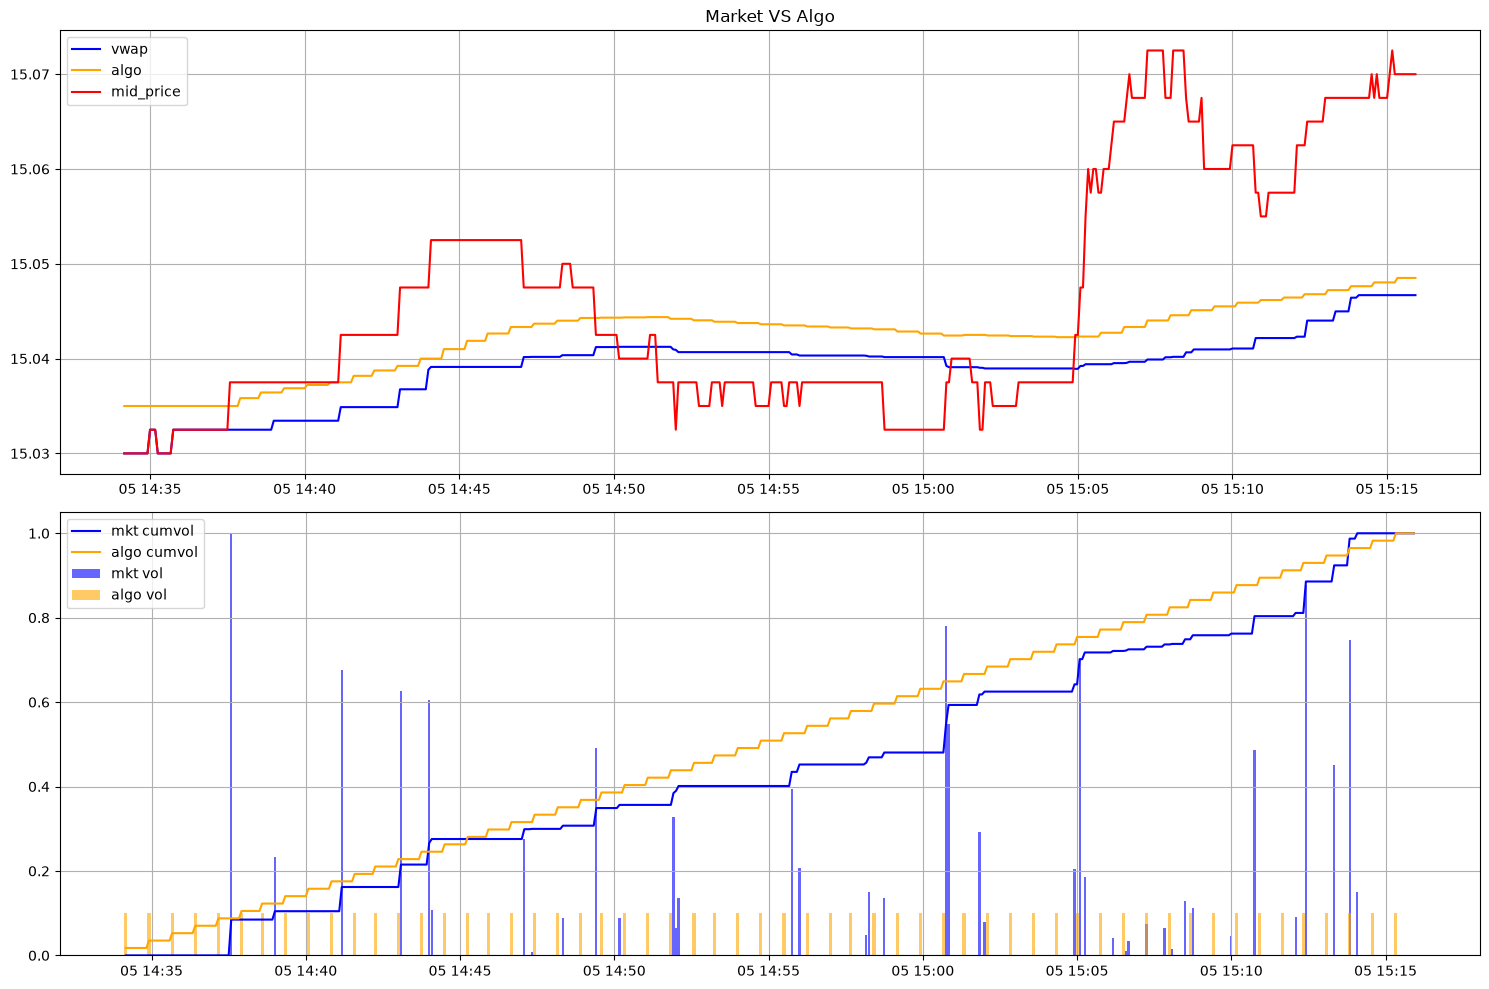

In [4]:
# Evaluación de la línea base determinista TWAP sobre el conjunto de test
set_seeds(42)
env_twap = BestExecutionEnv(dict_["test"], look_back=60)
twap_agent = TWAP(env_twap, buffer_size=100, batch_size=16)
twap_metrics = evaluate_episode(env_twap, twap_agent, seed=42)

print("Métricas del agente TWAP determinista en test:")
for k, v in twap_metrics.items():
    print(f"  {k}: {v:.4f}")

fig_twap = plot_results(
    env_twap,
    save_path=results_dir / "ej1_twap_baseline.png",
    show=True,
)

## [BLOQUE MODIFICADO: Parametrización del agente y del entrenamiento]

Se definen los hiperparámetros del agente Double DQN y del proceso de entrenamiento para completar la ejecución de extremo a extremo:
* **`epsilon = 0.9`**, **`min_epsilon = 0.05`**, **`epsilon_decay = 0.005`**: exploración inicial elevada que se reduce gradualmente al finalizar cada episodio hasta alcanzar un suelo del 5 %.
* **`gamma = 0.99`**: factor de descuento estándar del taller para tareas episódicas.
* **`alpha = 0.001`**: tasa de aprendizaje constante para el optimizador Adam en un entorno financiero no estacionario.
* **`buffer_size = 10000`** y **`batch_size = 64`**: tamaño de memoria de repetición y de lote para romper la correlación secuencial entre pasos consecutivos.
* **`hidden_neurons = 32`**: unidades por capa oculta en las redes primaria y objetivo.
* **`nepisodes = 200`**, **`n_log = 25`**, **`learn_after = batch_size`**, **`update_target_after = 10 * learn_after`**: frecuencias de actualización de pesos de la red principal y de sincronización de la red objetivo.

In [5]:
set_seeds(42)

# Parámetros del agente
epsilon = 0.9
min_epsilon = 0.05
gamma = 0.99
alpha = 0.001
buffer_size = 10000
batch_size = 64
hidden_neurons = 32

# Parámetros del entrenamiento
nepisodes = 200
n_log = 25
epsilon_decay = 0.005
learn_after = batch_size
update_target_after = 10 * learn_after

env = BestExecutionEnv(data, look_back=60)
agent = DDQNAgent(
    env=env,
    gamma=gamma,
    epsilon=epsilon,
    alpha=alpha,
    batch_size=batch_size,
    buffer_size=buffer_size,
    hidden_neurons=hidden_neurons,
    trainable=True,
)

## [BLOQUE MODIFICADO: Recolección inicial de experiencias para el buffer]

Antes de iniciar el ajuste de pesos de la red neuronal, se llena la memoria de repetición con `buffer_size` transiciones generadas mediante una política puramente aleatoria. En el cuaderno original del taller el comentario indicaba que `epsilon` valía 1 durante esta fase, pero el agente se inicializaba con `epsilon = 0.9`, por lo que en el 10 % de los pasos consultaba una red sin entrenar. En `fill_buffer` se sincroniza `agent.env = env`, se fuerza temporalmente `agent.epsilon = 1.0` durante toda la recolección inicial y se restaura el valor configurado (`0.9`) al concluir.

In [6]:
set_seeds(42)
fill_buffer(env, agent, buffer_steps=buffer_size, log_every=2500)
print(f"Experiencias almacenadas en el buffer: {len(agent.buffer)}")
print(f"Épsilon restaurado tras llenar el buffer: {agent.epsilon}")

buffer exps: 0
buffer exps: 2500


buffer exps: 5000
buffer exps: 7500


Experiencias almacenadas en el buffer: 10000
Épsilon restaurado tras llenar el buffer: 0.9


## [BLOQUE MODIFICADO: Bucle de entrenamiento de Double DQN]

Se ejecuta el entrenamiento durante `nepisodes = 200` episodios respetando el orden estricto de interacción con el entorno:
1. Reinicio del episodio: `s = env.reset()`.
2. Selección de acción: `a = agent.act(s)`.
3. Transición en el entorno: `s1, r, done, _ = env.step(a)`.
4. Almacenamiento en memoria: `agent.experience(s, a, r, s1, done)`.
5. Actualización de la red primaria cada `learn_after` pasos: `mse = agent.learn()`.
6. Copia de pesos a la red objetivo cada `update_target_after` pasos: `agent.update_target()`.
7. Al terminar el episodio (`done == True`), se aplica el decaimiento de `epsilon` y se registran las métricas acumuladas.

Se corrigen además dos defectos del bucle original del taller: se inicializa `mse = float("nan")` antes del entrenamiento para evitar un `UnboundLocalError` si un episodio concluye antes de alcanzar `learn_after` pasos, y se elimina la llamada adicional a `agent.learn()` dentro del bloque de registro periódico (`if episode % n_log == 0:`), de modo que el ajuste de pesos ocurra únicamente cada `learn_after` transiciones y el registro muestre el último `mse` calculado.

In [7]:
set_seeds(42)
history = train_agent(
    env=env,
    agent=agent,
    nepisodes=nepisodes,
    min_epsilon=min_epsilon,
    epsilon_decay=epsilon_decay,
    learn_after=learn_after,
    update_target_after=update_target_after,
    n_log=n_log,
    verbose=True,
)
history_steps = history["steps"]
history_rewards = history["rewards"]
history_disc_rewards = history["disc_rewards"]
history_losses = history["losses"]

Episode: 0, steps: 303.0, rew: -0.0124, mse: 3.1e-05, eps: 0.9


Episode: 25, steps: 315.92, rew: -0.1744, mse: 3e-06, eps: 0.77


Episode: 50, steps: 356.48, rew: -0.1035, mse: 1e-06, eps: 0.64


Episode: 75, steps: 394.12, rew: -0.162, mse: 0.000109, eps: 0.52


Episode: 100, steps: 236.32, rew: -0.2575, mse: 1.6e-05, eps: 0.39


Episode: 125, steps: 191.04, rew: -0.1926, mse: 2.4e-05, eps: 0.27


Episode: 150, steps: 237.4, rew: -0.2926, mse: 2.9e-05, eps: 0.14


Episode: 175, steps: 312.44, rew: -0.2235, mse: 5e-06, eps: 0.05


## [BLOQUE MODIFICADO: Evaluación del agente entrenado y gráficos de resultados]

Una vez finalizado el entrenamiento, en `evaluate_episode` se vincula temporalmente `agent.env = env_test` y se desactiva la exploración (`agent.set_trainable(False)`) para evaluar el comportamiento determinista del agente sobre un episodio del conjunto de test (`dict_["test"]`), restaurando el estado previo del agente al terminar. Se generan y almacenan las figuras de comparación entre el mercado y el algoritmo (`results/ej1_market_vs_algo.png`) y la evolución de la media móvil de 20 episodios de la recompensa de entrenamiento (`results/ej1_training_rewards.png`).

Como corresponde al planteamiento del Ejercicio 1, donde la recompensa inmediata solo compara el precio puntual de compra con el VWAP del episodio y no incorpora todavía una señal de seguimiento temporal del plan, el agente completa el flujo de aprendizaje de principio a fin pero tiende a concentrar las compras en lugar de distribuirlas uniformemente como un TWAP (objetivo que se aborda en el Ejercicio 2).

El algoritmo compra a `ask1` mientras que el VWAP de mercado usa el mid, así que el slippage incluye un coste estructural de medio spread (spread mediano de REP ≈ 3,55 pbs, medio spread ≈ 1,8 pbs, valores de referencia en train). El valor del episodio evaluado lo imprime la celda de evaluación siguiente como `avg_half_spread_bps`. Un slippage negativo de ese orden de magnitud no es un error del agente.

Métricas del agente DDQN en el episodio de evaluación (test):
  avg_half_spread_bps: 2.0455
  steps: 57.0000
  exec_vol: 57.0000
  vol_care: 57.0000
  cum_reward: 0.0390
  disc_cum_reward: 0.0306
  algo_vwap: 15.0364
  market_vwap: 15.0467
  vwap_slippage_bps: 6.8383


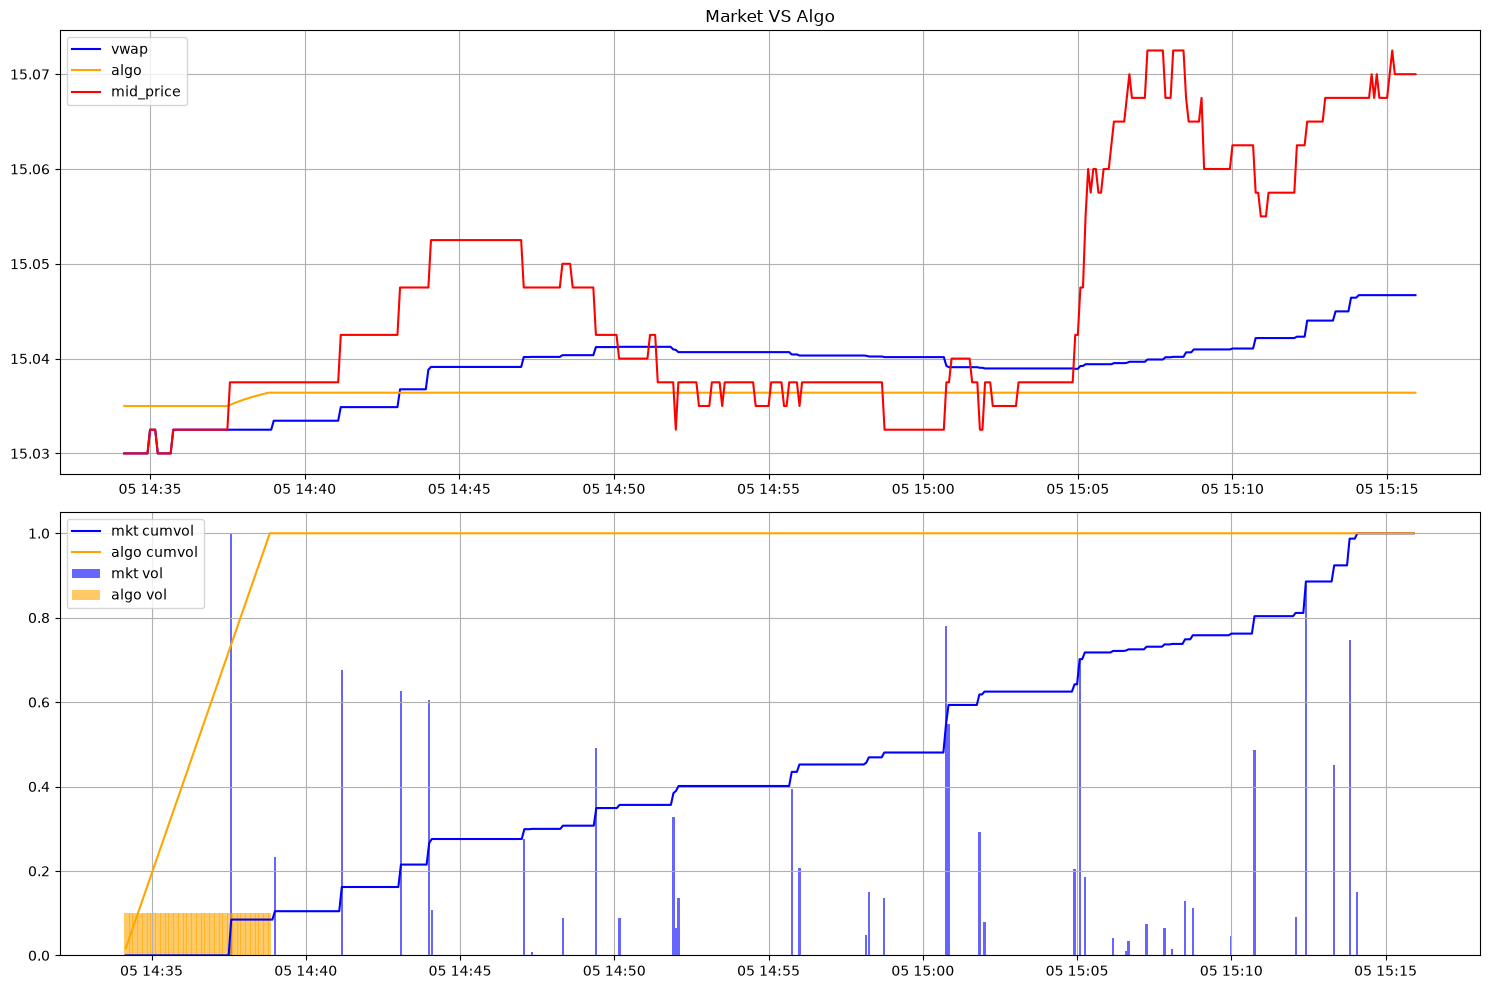

In [8]:
env_test = BestExecutionEnv(dict_["test"], look_back=60)
eval_metrics = evaluate_episode(env_test, agent, seed=42)

print("Métricas del agente DDQN en el episodio de evaluación (test):")
for k, v in eval_metrics.items():
    print(f"  {k}: {v:.4f}")

fig_algo = plot_results(
    env_test,
    save_path=results_dir / "ej1_market_vs_algo.png",
    show=True,
)

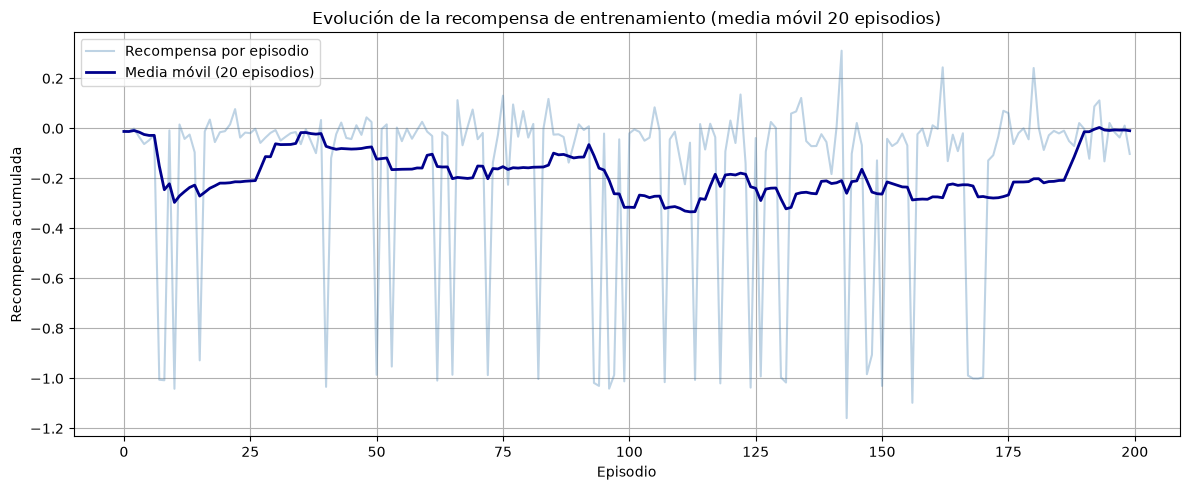

In [9]:
fig_rew = plot_training_rewards(
    history_rewards,
    window=20,
    save_path=results_dir / "ej1_training_rewards.png",
    show=True,
)